In [293]:
import rustworkx as rx
import numpy as np
from rustworkx.visualization import mpl_draw as draw_graph

np.random.seed(0)
n = 25  # Number of nodes
edge_prob = 0.25  # Probability of edge between any pair of nodes

adj_matrix = np.triu((np.random.rand(n, n) < edge_prob).astype(float), 1)
adj_matrix += adj_matrix.T
# adj_matrix

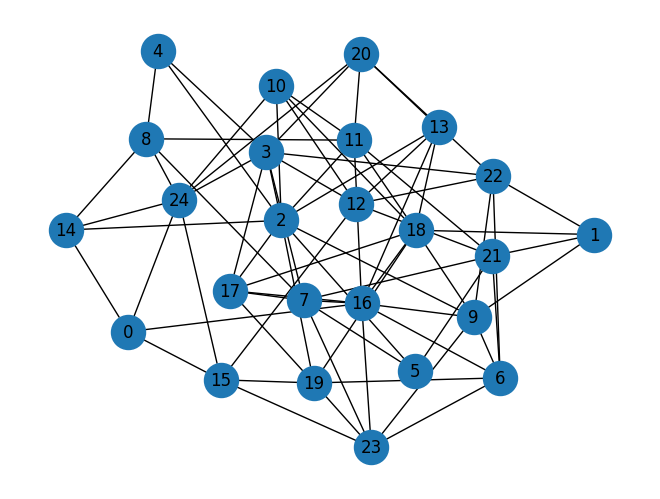

In [294]:
graph = rx.PyGraph.from_adjacency_matrix(adj_matrix)
draw_graph(graph, node_size=600, with_labels=True)

In [295]:
import networkx as nx

er_graph = nx.erdos_renyi_graph(n=25, p=0.2)
adj_matrix_er = nx.adjacency_matrix(er_graph).todense()

ba_graph = nx.barabasi_albert_graph(n=25, m=2)
adj_matrix_ba = nx.adjacency_matrix(ba_graph).todense()

regular_graph = nx.random_regular_graph(d=4, n=25)
adj_matrix_reg = nx.adjacency_matrix(regular_graph).todense()

# Small-world network
ws_graph = nx.watts_strogatz_graph(n=25, k=4, p=0.3)
adj_matrix_ws = nx.adjacency_matrix(ws_graph).todense()

In [296]:
# graph=er_graph
# adj_matrix = adj_matrix_er

# graph=ba_graph
# adj_matrix = adj_matrix_ba

# graph=regular_graph
# adj_matrix = adj_matrix_reg

# graph=ws_graph
# adj_matrix = adj_matrix_ws

In [297]:
from qiskit.quantum_info import SparsePauliOp
def build_max_cut_paulis(graph: rx.PyGraph) -> list[tuple[str, float]]:
    """Convert the graph to Pauli list.

    This function does the inverse of `build_max_cut_graph`
    """
    pauli_list = []
    for edge in list(graph.edge_list()):
        paulis = ["I"] * len(graph)
        paulis[edge[0]], paulis[edge[1]] = "Z", "Z"

        weight = graph.get_edge_data(edge[0], edge[1])

        pauli_list.append(("".join(paulis)[::-1], weight))

    return pauli_list

def build_max_cut_paulis_nx(graph: nx.Graph) -> list[tuple[str, float]]:
    """Convert NetworkX graph to Pauli list for MaxCut."""
    pauli_list = []
    num_nodes = len(graph.nodes())
    
    for edge in graph.edges(data=True):
        u, v, data = edge
        paulis = ["I"] * num_nodes
        
        # NetworkX nodes can be any hashable type, so we use positional indices
        paulis[u] = "Z"
        paulis[v] = "Z"
        
        # Get weight with default 1.0 if not specified
        weight = data.get('weight', 1.0)
        
        # Reverse string to match RustworkX qubit ordering convention
        pauli_list.append(("".join(paulis)[::-1], float(weight)))
    
    return pauli_list



max_cut_paulis = build_max_cut_paulis(graph)
# max_cut_paulis = build_max_cut_paulis_nx(graph)

cost_hamiltonian = SparsePauliOp.from_list(max_cut_paulis)
print("Cost Function Hamiltonian:", cost_hamiltonian)

Cost Function Hamiltonian: SparsePauliOp(['IIIIIIIIIIZIIIIIIIIIIIIIZ', 'IIIIIIIIIZIIIIIIIIIIIIIIZ', 'IIIIIIIIZIIIIIIIIIIIIIIIZ', 'ZIIIIIIIIIIIIIIIIIIIIIIIZ', 'IIIIIIIIIIIIIIIZIIIIIIIZI', 'IIIIIIZIIIIIIIIIIIIIIIIZI', 'IIIZIIIIIIIIIIIIIIIIIIIZI', 'IIZIIIIIIIIIIIIIIIIIIIIZI', 'IIIIIIIIIIIIIIIIIIIIIZZII', 'IIIIIIIIIIIIIIIIIIIIZIZII', 'IIIIIIIIIIIIIIIIIIIZIIZII', 'IIIIIIIIIIIIIIIZIIIIIIZII', 'IIIIIIIIIIIIIIZIIIIIIIZII', 'IIIIIIIIIIIIIZIIIIIIIIZII', 'IIIIIIIIIIIZIIIIIIIIIIZII', 'IIIIIIIIIIZIIIIIIIIIIIZII', 'IIIIIIIZIIIIIIIIIIIIIIZII', 'IIIIIZIIIIIIIIIIIIIIIIZII', 'IIIIIIIIIIIIIIIIIIIIZZIII', 'IIIIIIIIIIIIIIIIIZIIIZIII', 'IIIIIIIIIIIIZIIIIIIIIZIII', 'IIIIIIIZIIIIIIIIIIIIIZIII', 'IIIIZIIIIIIIIIIIIIIIIZIII', 'IIZIIIIIIIIIIIIIIIIIIZIII', 'ZIIIIIIIIIIIIIIIIIIIIZIII', 'IIIIIIIIIIIIIIIIZIIIZIIII', 'IIIIIIIIIIIIIIIIIZIZIIIII', 'IIIZIIIIIIIIIIIIIIIZIIIII', 'IIIIIIIIIIIIIIIZIIZIIIIII', 'IIIIIIIIZIIIIIIIIIZIIIIII', 'IIIIIZIIIIIIIIIIIIZIIIIII', 'IIIZIIIIIIIIIIIIIIZIIIIII', 'IIZIIIIIIIIIIIIIIIZIIIIII', '

In [298]:
from qiskit.circuit.library import QAOAAnsatz

reps=3
circuit = QAOAAnsatz(cost_operator=cost_hamiltonian, reps=reps)
circuit.measure_all()

# circuit.draw('mpl')

Initialize Params

In [299]:
initial_gamma = np.pi
initial_beta = np.pi/2
init_params = [initial_gamma, initial_beta] * reps

In [300]:
objective_func_vals = [] # Global variable

def cost_func_estimator(params, ansatz, hamiltonian, estimator):
    isa_hamiltonian = hamiltonian.apply_layout(ansatz.layout)

    pub = (ansatz, isa_hamiltonian, params)
    job = estimator.run([pub])

    results = job.result()[0]
    cost = results.data.evs

    objective_func_vals.append(cost)

    return cost

In [301]:
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService(channel='ibm_quantum', token='205d1b23f51dba2efe445b1b44f1e07939499dba4f4343c67d9004c25b833489b950240921dc782935c419c08569dbc6d642584e5835a97fde387586b542d8ac')
backend = service.backend('ibm_brisbane')
print(backend)

C:\Users\devra\AppData\Local\Temp\ipykernel_38832\3147300818.py:3: DeprecationWarning: The "ibm_quantum" channel option is deprecated and will be sunset on 1 July. After this date, "ibm_cloud" and "local" will be the only valid channels. For information on migrating to the new IBM Quantum Platform on the "ibm_cloud" channel, review the migration guide https://quantum.cloud.ibm.com/docs/migration-guides/classic-iqp-to-cloud-iqp .
  service = QiskitRuntimeService(channel='ibm_quantum', token='205d1b23f51dba2efe445b1b44f1e07939499dba4f4343c67d9004c25b833489b950240921dc782935c419c08569dbc6d642584e5835a97fde387586b542d8ac')


<IBMBackend('ibm_brisbane')>


In [302]:
basis_gates = backend.basis_gates
basis_gates

['ecr', 'id', 'rz', 'sx', 'x']

In [303]:
coupling_map = backend.coupling_map

# Get adjacency as a dict: {qubit: [connected_qubits]}
adj = {i: [] for i in range(backend.configuration().num_qubits)}
for (i, j) in coupling_map:
    adj[i].append(j)
    adj[j].append(i)

# Greedy DFS to build a chain
def find_linear_chain(adj, length):
    for start in adj:
        path = [start]
        visited = {start}
        while len(path) < length:
            last = path[-1]
            next_nodes = [n for n in adj[last] if n not in visited]
            if not next_nodes:
                break
            next_node = next_nodes[0]
            path.append(next_node)
            visited.add(next_node)
        if len(path) == length:
            return path
    return None

chain = find_linear_chain(adj, n)  # Length = number of qubits = nodes
chain

[7,
 6,
 5,
 4,
 3,
 2,
 1,
 0,
 14,
 18,
 19,
 20,
 33,
 39,
 38,
 37,
 52,
 56,
 57,
 58,
 59,
 60,
 53,
 41,
 40]

In [304]:
# sorted_indices[i] is the logical qubit index (graph node)
# chain[i] is the physical qubit index
logical_to_physical = {i: chain[i] for i in range(n)}
logical_to_physical

{0: 7,
 1: 6,
 2: 5,
 3: 4,
 4: 3,
 5: 2,
 6: 1,
 7: 0,
 8: 14,
 9: 18,
 10: 19,
 11: 20,
 12: 33,
 13: 39,
 14: 38,
 15: 37,
 16: 52,
 17: 56,
 18: 57,
 19: 58,
 20: 59,
 21: 60,
 22: 53,
 23: 41,
 24: 40}

In [305]:
from qiskit.transpiler import Layout

initial_layout = Layout({q: logical_to_physical[i] for i,q in enumerate(circuit.qubits)})
initial_layout

Layout({
7: <Qubit register=(25, "q"), index=0>,
6: <Qubit register=(25, "q"), index=1>,
5: <Qubit register=(25, "q"), index=2>,
4: <Qubit register=(25, "q"), index=3>,
3: <Qubit register=(25, "q"), index=4>,
2: <Qubit register=(25, "q"), index=5>,
1: <Qubit register=(25, "q"), index=6>,
0: <Qubit register=(25, "q"), index=7>,
14: <Qubit register=(25, "q"), index=8>,
18: <Qubit register=(25, "q"), index=9>,
19: <Qubit register=(25, "q"), index=10>,
20: <Qubit register=(25, "q"), index=11>,
33: <Qubit register=(25, "q"), index=12>,
39: <Qubit register=(25, "q"), index=13>,
38: <Qubit register=(25, "q"), index=14>,
37: <Qubit register=(25, "q"), index=15>,
52: <Qubit register=(25, "q"), index=16>,
56: <Qubit register=(25, "q"), index=17>,
57: <Qubit register=(25, "q"), index=18>,
58: <Qubit register=(25, "q"), index=19>,
59: <Qubit register=(25, "q"), index=20>,
60: <Qubit register=(25, "q"), index=21>,
53: <Qubit register=(25, "q"), index=22>,
41: <Qubit register=(25, "q"), index=23>,
4

In [306]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit import transpile

basis_change = transpile(circuit, basis_gates=basis_gates, seed_transpiler=0)
# basis_change.draw('mpl', fold=False)

In [307]:
from qiskit.transpiler import PassManager, CouplingMap, Layout
from qiskit.transpiler.passes import (
    SetLayout,
    EnlargeWithAncilla,
    FullAncillaAllocation,
    ApplyLayout,
    SabreSwap,
    SabreLayout
)

coupling_map = CouplingMap(backend.configuration().coupling_map)

# Create custom PassManager to stop at SabreSwap
pm = PassManager([
    SetLayout(initial_layout),
    # SabreLayout(coupling_map),
    EnlargeWithAncilla(),
    FullAncillaAllocation(coupling_map),
    ApplyLayout(),
    SabreSwap(coupling_map, heuristic='basic', seed=0)
])

# Transpile using the custom pipeline
transpiled = pm.run(basis_change)

# View the circuit with SWAP gates intact
# print(transpiled)
print("SWAP gates inserted:", transpiled.count_ops().get("swap", 0))

SWAP gates inserted: 788


In [308]:
transpiled.draw('mpl', fold=False)